# <center> House Price Prediction

 # <center> Data Pre-processing: Missing Values

## Handling Missing Values 

In [184]:
#import libreries

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import data_profiling as yp
import warnings
warnings.filterwarnings("ignore")

In [185]:
# Load data
housing_data_path = Path("../datasets/housing.csv") 
df = pd.read_csv(housing_data_path)
# data info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 83 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       2930 non-null   int64  
 1   Order            2930 non-null   int64  
 2   PID              2930 non-null   int64  
 3   MS SubClass      2930 non-null   int64  
 4   MS Zoning        2930 non-null   object 
 5   Lot Frontage     2440 non-null   float64
 6   Lot Area         2930 non-null   int64  
 7   Street           2930 non-null   object 
 8   Alley            198 non-null    object 
 9   Lot Shape        2930 non-null   object 
 10  Land Contour     2930 non-null   object 
 11  Utilities        2930 non-null   object 
 12  Lot Config       2930 non-null   object 
 13  Land Slope       2930 non-null   object 
 14  Neighborhood     2930 non-null   object 
 15  Condition 1      2930 non-null   object 
 16  Condition 2      2930 non-null   object 
 17  Bldg Type     

In [186]:
# describe data
df.describe()

,Unnamed: 0,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1464.50000,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,0.00000,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,732.25000,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1464.50000,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2196.75000,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2929.00000,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


In [187]:
def missing_values(data):
    """Return columns containing missing values and their counts."""
    counts = data.isna().sum()
    return counts[counts > 0].sort_values(ascending=False).rename("Missing Count")

missing_values(df)

Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Cond        159
Garage Qual        159
Garage Finish      159
Garage Yr Blt      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
Bsmt Qual           80
BsmtFin Type 1      80
Mas Vnr Area        23
Bsmt Half Bath       2
Bsmt Full Bath       2
BsmtFin SF 1         1
Garage Cars          1
Garage Area          1
Total Bsmt SF        1
Bsmt Unf SF          1
BsmtFin SF 2         1
Electrical           1
Name: Missing Count, dtype: int64

In [188]:
df.isna().sum()

Unnamed: 0        0
Order             0
PID               0
MS SubClass       0
MS Zoning         0
                 ..
Mo Sold           0
Yr Sold           0
Sale Type         0
Sale Condition    0
SalePrice         0
Length: 83, dtype: int64

In [189]:
# Keep columns with at least 2,770 non-null values
#df = df.dropna(axis=1, thresh=2770)

In [190]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 83 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       2930 non-null   int64  
 1   Order            2930 non-null   int64  
 2   PID              2930 non-null   int64  
 3   MS SubClass      2930 non-null   int64  
 4   MS Zoning        2930 non-null   object 
 5   Lot Frontage     2440 non-null   float64
 6   Lot Area         2930 non-null   int64  
 7   Street           2930 non-null   object 
 8   Alley            198 non-null    object 
 9   Lot Shape        2930 non-null   object 
 10  Land Contour     2930 non-null   object 
 11  Utilities        2930 non-null   object 
 12  Lot Config       2930 non-null   object 
 13  Land Slope       2930 non-null   object 
 14  Neighborhood     2930 non-null   object 
 15  Condition 1      2930 non-null   object 
 16  Condition 2      2930 non-null   object 
 17  Bldg Type     

In [191]:
# fill missing values for LotFrontage based on the median of their specific Neighborhood

# Step 1: Fill missing values with the median of their specific Neighborhood
df['Lot Frontage'] = df.groupby('Neighborhood')['Lot Frontage'].transform(
    lambda x: x.fillna(x.median())
)

# Step 2: Fallback for any remaining NaNs 
# (This edge case occurs if an entire Neighborhood has 100% missing LotFrontage data)
global_median = df['Lot Frontage'].median()
df['Lot Frontage'] = df['Lot Frontage'].fillna(global_median)

# Verification
print(f"Lot Frontage missing values remaining: {df['Lot Frontage'].isna().sum()}")

Lot Frontage missing values remaining: 0


<Axes: >

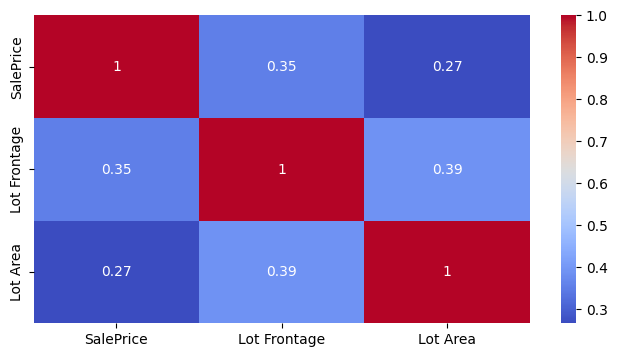

In [192]:
# Check the correlation between SalePrice and Lot Frontage, Lot Area
numeric_cols = df.select_dtypes(include=["number","int64","float64"])
plt.figure(figsize=(8, 4))
sns.heatmap(numeric_cols[["SalePrice","Lot Frontage","Lot Area"]].corr(), annot=True, cmap='coolwarm')

In [193]:
# Fill missing values for numeric columns with the mean of the column
numeric_cols = df.select_dtypes(include="number").columns
for col in numeric_cols:
    if df[col].isnull().sum()>0 :
        # Print the number of missing values in the column
        
        print(f"Missing values in {col} are : ")
        print(df[col].isnull().sum()  )
        
        # Check the value counts in the column
        print(f"Value counts in {col} :")
        print(df[col].value_counts().head(5))
        
        # fill missing values with 0.0 as it is a numeric column and missing values can be considered as no value.
        df[col] = df[col].fillna(0.0)



Missing values in Mas Vnr Area are : 
23
Value counts in Mas Vnr Area :
Mas Vnr Area
0.0      1748
120.0      15
176.0      13
200.0      13
216.0      12
Name: count, dtype: int64
Missing values in BsmtFin SF 1 are : 
1
Value counts in BsmtFin SF 1 :
BsmtFin SF 1
0.0      930
24.0      27
16.0      14
300.0      9
20.0       8
Name: count, dtype: int64
Missing values in BsmtFin SF 2 are : 
1
Value counts in BsmtFin SF 2 :
BsmtFin SF 2
0.0      2578
294.0       5
180.0       5
162.0       3
435.0       3
Name: count, dtype: int64
Missing values in Bsmt Unf SF are : 
1
Value counts in Bsmt Unf SF :
Bsmt Unf SF
0.0      244
384.0     19
728.0     14
672.0     13
600.0     12
Name: count, dtype: int64
Missing values in Total Bsmt SF are : 
1
Value counts in Total Bsmt SF :
Total Bsmt SF
0.0       79
864.0     74
672.0     29
912.0     26
1040.0    25
Name: count, dtype: int64
Missing values in Bsmt Full Bath are : 
2
Value counts in Bsmt Full Bath :
Bsmt Full Bath
0.0    1707
1.0    1181


## Handling Missing Values in Categorical Features

In [211]:
# Fill missing values for categorical columns with the string "Missing"
cat_cols = df.select_dtypes(include=["object", "category", "string"]).columns.tolist()
print("Nubmer of messing values in categorical features: ")
print(".................................................")
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        print(f"Missing values in {col}: {df[col].isnull().sum()}")
        
cat_cols.remove("Electrical")
df[cat_cols] = df[cat_cols].fillna("Na")


Nubmer of messing values in categorical features: 
.................................................
Missing values in Alley: 2732
Missing values in Mas Vnr Type: 1775
Missing values in Bsmt Qual: 80
Missing values in Bsmt Cond: 80
Missing values in Bsmt Exposure: 83
Missing values in BsmtFin Type 1: 80
Missing values in BsmtFin Type 2: 81
Missing values in Fireplace Qu: 1422
Missing values in Garage Type: 157
Missing values in Garage Finish: 159
Missing values in Garage Qual: 159
Missing values in Garage Cond: 159
Missing values in Pool QC: 2917
Missing values in Fence: 2358
Missing values in Misc Feature: 2824


In [212]:
# Fill missing values for Electrical with the mode of the column, 
# as it is a categorical column and missing values can be considered as the most common electrical system.
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

In [196]:
# Check if messing values are filled
f"the number of missing values in the dataset is: {missing_values(df).count()}"

'the number of missing values in the dataset is: 0'

In [213]:
df.isna().sum().sum()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 84 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0.1     2930 non-null   int64  
 1   Unnamed: 0       2930 non-null   int64  
 2   Order            2930 non-null   int64  
 3   PID              2930 non-null   int64  
 4   MS SubClass      2930 non-null   int64  
 5   MS Zoning        2930 non-null   object 
 6   Lot Frontage     2930 non-null   float64
 7   Lot Area         2930 non-null   int64  
 8   Street           2930 non-null   object 
 9   Alley            2930 non-null   object 
 10  Lot Shape        2930 non-null   object 
 11  Land Contour     2930 non-null   object 
 12  Utilities        2930 non-null   object 
 13  Lot Config       2930 non-null   object 
 14  Land Slope       2930 non-null   object 
 15  Neighborhood     2930 non-null   object 
 16  Condition 1      2930 non-null   object 
 17  Condition 2   

In [214]:
# Importing new data
df.to_csv("../datasets/housing_no_missing_values.csv")

In [215]:
df[numeric_cols].isnull().sum().sum()
df[cat_cols].isnull().sum().sum()

0

In [216]:
df = pd.read_csv("../datasets/housing_no_missing_values.csv")
for col in cat_cols:
    print(df[col].isna().sum())


0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
